# Chai Cafe Orders: Cleaning and Analysis (September 2026)

**Data:** `chai_cafe_orders.csv` (304 rows, 10 columns; one row = one order).

**Questions**
1. How much did the cafe earn, and which branch earns the most?
2. Which items and categories bring in the money?
3. How do customers pay?
4. Do age, ratings or dates show any pattern?

---
## Conclusion

**Total revenue was 37,215** (from 298 orders with a known quantity; 300 orders in total).

1. **Bandra leads.** It earns 16,400 (about 44% of the total) from 317 units. Andheri and Powai earn almost the same (10,400 and 10,415), even though Andheri sold about 50 more units (241 vs 192). The reason is revenue per unit: Powai earns about 54 per unit and Andheri about 43, which suggests Powai's customers buy pricier items.
2. **A higher price can beat a higher quantity.** Cold Coffee earns the most (8,520, about 23% of the total) from only 71 units, because it costs 120. Cheesecake sold the fewest units (31) but is third in revenue (4,650). In contrast, Cutting Chai is second in units (97) but last in revenue (1,455). Beverages bring in about half of all revenue (18,435).
3. **UPI is the most popular way to pay.** It is 54% of orders (163 of 300) and 52% of revenue (19,435), and it leads in all three branches.
4. **No clear pattern elsewhere.** Average age is similar across categories (36.5 to 38.8), average ratings are similar across branches (3.57 to 3.69 out of 5), and daily revenue goes up and down with no trend or reliable weekday pattern, so none of these gives a basis for decisions.

**Data notes:** I removed 4 duplicate rows (304 to 300 orders). I set 2 impossible values in Quantity (-2 and 60) and 1 in Customer_Age (250) to blank, and corrected one Unit_Price of 3000 to 30, the item's menu price. Six blank Payment_Mode values were labelled "Unknown", and the 18 blank Ratings were left as they are. Branch names were standardized (11 spellings reduced to 3). As a result, revenue totals exclude 2 orders, and the average rating is based on 282 ratings.

---
## Cleaning log
- Order_Date: converted text to date
- Payment_Mode: 6 blanks -> "Unknown"
- Rating: 18 blanks left as they are (excluded from averages)
- Duplicates: 4 removed (304 -> 300 rows)
- Branch: 11 spellings -> 3 (strip + title)
- Quantity: 2 impossible values (-2, 60) -> blank
- Unit_Price: 3000 -> 30 (menu price)
- Customer_Age: 250 -> blank

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/chai_cafe_orders.csv")   # path in Google Colab
df.shape

(304, 10)

In [2]:
df.dtypes

Order_ID            str
Order_Date          str
Item                str
Category            str
Quantity          int64
Unit_Price        int64
Branch              str
Payment_Mode        str
Customer_Age      int64
Rating          float64
dtype: object

## 2. Clean the data
### Dates

In [3]:
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Order_Date'].min(), df['Order_Date'].max()

(Timestamp('2026-09-01 00:00:00'), Timestamp('2026-09-30 00:00:00'))

### Missing values

In [4]:
df.isnull().sum()

Order_ID         0
Order_Date       0
Item             0
Category         0
Quantity         0
Unit_Price       0
Branch           0
Payment_Mode     6
Customer_Age     0
Rating          18
dtype: int64

In [5]:
df['Payment_Mode'] = df['Payment_Mode'].fillna('Unknown')   # 6 blanks labelled
df['Payment_Mode'].value_counts()

Payment_Mode
UPI        165
Cash        82
Card        51
Unknown      6
Name: count, dtype: int64

`Rating` has 18 blanks. We leave them blank, because pandas skips blanks when averaging and we do not want to invent ratings.

### Duplicates

In [6]:
print(df.duplicated().sum())          # 4 found
df = df.drop_duplicates()
print(df.shape, df.duplicated().sum())

4
(300, 10) 0


### Text spelling

In [7]:
for col in ['Item', 'Category', 'Branch', 'Payment_Mode']:
    print(col)
    print(df[col].value_counts())
    print()

Item
Item
Masala Chai      66
Cutting Chai     44
Vada Pav         31
Bun Maska        29
Samosa           29
Cold Coffee      26
Filter Coffee    25
Sandwich         19
Brownie          19
Cheesecake       12
Name: count, dtype: int64

Category
Category
Beverage    161
Snack       108
Dessert      31
Name: count, dtype: int64

Branch
Branch
Bandra     120
Andheri     95
Powai       73
andheri      3
POWAI        2
Bandra       2
ANDHERI      1
bandra       1
BANDRA       1
powai        1
Powai        1
Name: count, dtype: int64

Payment_Mode
Payment_Mode
UPI        163
Cash        81
Card        50
Unknown      6
Name: count, dtype: int64



In [8]:
df['Branch'] = df['Branch'].str.strip().str.title()
df['Branch'].value_counts()

Branch
Bandra     124
Andheri     99
Powai       77
Name: count, dtype: int64

### Impossible values

In [9]:
df.describe()

,Order_Date,Quantity,Unit_Price,Customer_Age,Rating
count,300,300.000000,300.000000,300.000000,282.000000
mean,2026-09-15 22:09:36,2.693333,58.766667,38.576667,3.638298
min,2026-09-01 00:00:00,-2.000000,15.000000,5.000000,1.000000
25%,2026-09-08 00:00:00,2.000000,25.000000,27.000000,3.000000
50%,2026-09-17 00:00:00,3.000000,30.000000,37.000000,4.000000
75%,2026-09-24 00:00:00,3.000000,80.000000,50.000000,4.750000
max,2026-09-30 00:00:00,60.000000,3000.000000,250.000000,5.000000
std,NaN,3.497628,174.539467,17.669129,1.152294


In [10]:
print(df[df['Quantity'] < 0][['Item', 'Quantity']])
print(df[df['Quantity'] > 10][['Item', 'Quantity']])
print(df[df['Unit_Price'] > 500][['Item', 'Unit_Price']])
print(df[df['Customer_Age'] > 100][['Item', 'Customer_Age']])
df.groupby('Item')['Unit_Price'].agg(['min', 'max'])   # each item has a fixed menu price

            Item  Quantity
203  Masala Chai        -2
        Item  Quantity
142  Brownie        60
            Item  Unit_Price
260  Masala Chai        3000
           Item  Customer_Age
17  Masala Chai           250


,min,max
Item,,
Brownie,80,80
Bun Maska,35,35
Cheesecake,150,150
Cold Coffee,120,120
Cutting Chai,15,15
Filter Coffee,60,60
Masala Chai,30,3000
Samosa,20,20
Sandwich,90,90


In [11]:
# Price: correct to the known menu price (Masala Chai = 30)
df.loc[df['Unit_Price'] > 500, 'Unit_Price'] = 30
# Quantity and age: impossible and not knowable -> blank
df.loc[(df['Quantity'] < 0) | (df['Quantity'] > 10), 'Quantity'] = np.nan
df.loc[df['Customer_Age'] > 100, 'Customer_Age'] = np.nan

df.describe()

,Order_Date,Quantity,Unit_Price,Customer_Age,Rating
count,300,298.000000,300.000000,299.000000,282.000000
mean,2026-09-15 22:09:36,2.516779,48.866667,37.869565,3.638298
min,2026-09-01 00:00:00,1.000000,15.000000,5.000000,1.000000
25%,2026-09-08 00:00:00,2.000000,25.000000,27.000000,3.000000
50%,2026-09-17 00:00:00,3.000000,30.000000,37.000000,4.000000
75%,2026-09-24 00:00:00,3.000000,80.000000,50.000000,4.750000
max,2026-09-30 00:00:00,4.000000,150.000000,59.000000,5.000000
std,NaN,1.073739,37.892414,12.757142,1.152294


In [12]:
df.isnull().sum()

Order_ID         0
Order_Date       0
Item             0
Category         0
Quantity         2
Unit_Price       0
Branch           0
Payment_Mode     0
Customer_Age     1
Rating          18
dtype: int64

## 3. Build Revenue

In [13]:
df['Revenue'] = df['Quantity'] * df['Unit_Price']
print('Total revenue:', df['Revenue'].sum(), ' orders with revenue:', df['Revenue'].count())

Total revenue: 37215.0  orders with revenue: 298


## 4. Branch analysis

In [14]:
branch = df.groupby('Branch')[['Quantity', 'Revenue']].sum()
branch['Orders'] = df['Branch'].value_counts()
branch['Revenue_per_unit'] = (branch['Revenue'] / branch['Quantity']).round(2)
branch['Avg_revenue_per_order'] = df.groupby('Branch')['Revenue'].mean().round(1)
branch.sort_values('Revenue', ascending=False)

,Quantity,Revenue,Orders,Revenue_per_unit,Avg_revenue_per_order
Branch,,,,,
Bandra,317.0,16400.0,124,51.74,132.3
Powai,192.0,10415.0,77,54.24,137.0
Andheri,241.0,10400.0,99,43.15,106.1


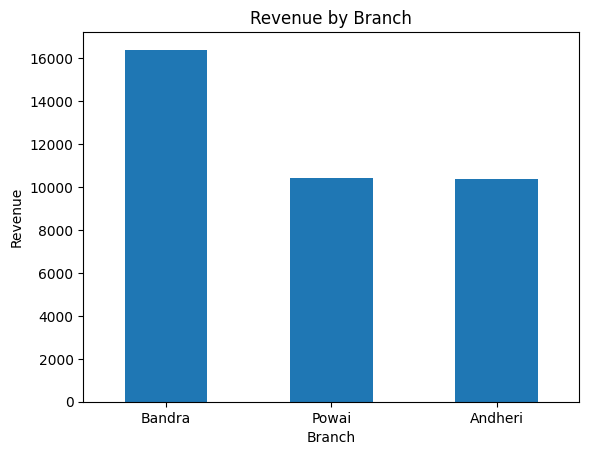

In [15]:
rev = df.groupby('Branch')['Revenue'].sum().sort_values(ascending=False)
rev.plot(kind='bar')
plt.title('Revenue by Branch'); plt.xlabel('Branch'); plt.ylabel('Revenue')
plt.xticks(rotation=0); plt.show()

## 5. Items and categories

In [16]:
items = df.groupby('Item')[['Quantity', 'Revenue']].sum()
items['Revenue_per_unit'] = items['Revenue'] / items['Quantity']
items.sort_values('Revenue', ascending=False)

,Quantity,Revenue,Revenue_per_unit
Item,,,
Cold Coffee,71.0,8520.0,120.0
Masala Chai,170.0,5100.0,30.0
Cheesecake,31.0,4650.0,150.0
Sandwich,48.0,4320.0,90.0
Brownie,48.0,3840.0,80.0
Filter Coffee,56.0,3360.0,60.0
Bun Maska,65.0,2275.0,35.0
Vada Pav,83.0,2075.0,25.0
Samosa,81.0,1620.0,20.0


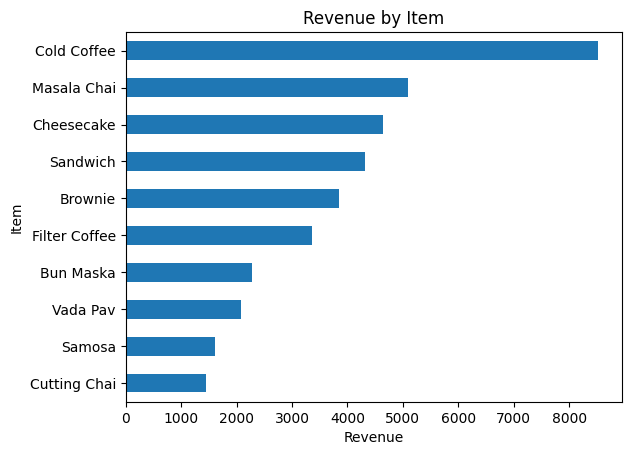

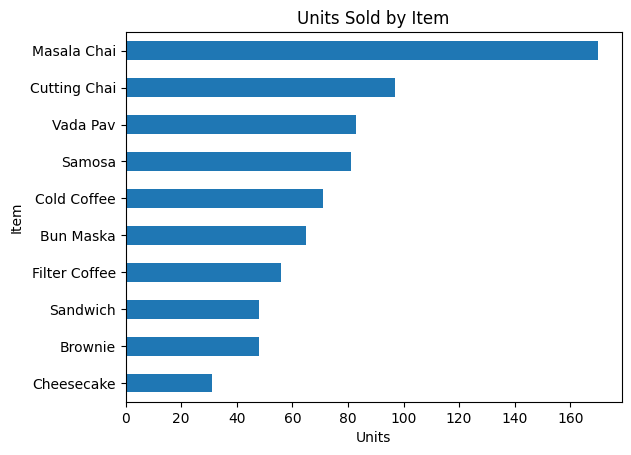

In [17]:
item_rev = df.groupby('Item')['Revenue'].sum().sort_values()
item_rev.plot(kind='barh')
plt.title('Revenue by Item'); plt.xlabel('Revenue'); plt.ylabel('Item'); plt.show()

item_qty = df.groupby('Item')['Quantity'].sum().sort_values()
item_qty.plot(kind='barh')
plt.title('Units Sold by Item'); plt.xlabel('Units'); plt.ylabel('Item'); plt.show()

In [18]:
df.groupby('Category')['Revenue'].sum().sort_values(ascending=False)

Category
Beverage    18435.0
Snack       10290.0
Dessert      8490.0
Name: Revenue, dtype: float64

## 6. Payment modes (orders, units and revenue)

In [19]:
share = pd.DataFrame({
    'Orders': df['Payment_Mode'].value_counts(),
    'Units': df.groupby('Payment_Mode')['Quantity'].sum(),
    'Revenue': df.groupby('Payment_Mode')['Revenue'].sum()})
print(share)
(share / share.sum() * 100).round(1)

              Orders  Units  Revenue
Payment_Mode                        
Card              50  129.0   6455.0
Cash              81  214.0  11065.0
UPI              163  396.0  19435.0
Unknown            6   11.0    260.0


,Orders,Units,Revenue
Payment_Mode,,,
Card,16.7,17.2,17.3
Cash,27.0,28.5,29.7
UPI,54.3,52.8,52.2
Unknown,2.0,1.5,0.7


In [20]:
pd.crosstab(df['Branch'], df['Payment_Mode'], normalize='index').round(3)

Payment_Mode,Card,Cash,UPI,Unknown
Branch,,,,
Andheri,0.141,0.273,0.545,0.040
Bandra,0.161,0.298,0.532,0.008
Powai,0.208,0.221,0.558,0.013


## 7. Age, ratings and time

In [21]:
age_tbl = df.groupby('Category')['Customer_Age'].agg(['mean', 'count']).round(1)
rating_tbl = df.groupby('Branch')['Rating'].agg(['mean', 'count']).round(2)
print(age_tbl); print(rating_tbl)

          mean  count
Category             
Beverage  38.8    160
Dessert   38.2     31
Snack     36.5    108
         mean  count
Branch              
Andheri  3.69     94
Bandra   3.64    118
Powai    3.57     70


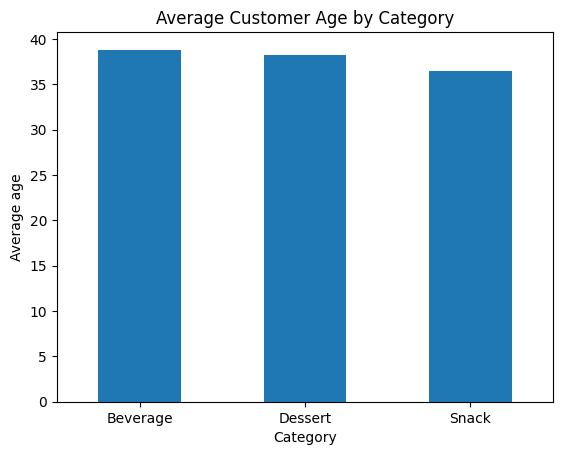

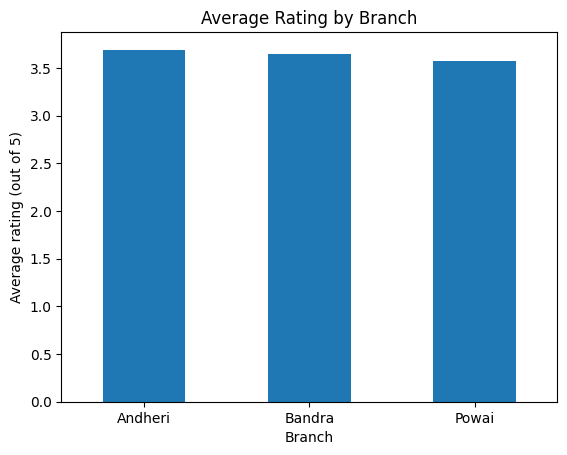

In [22]:
age_tbl['mean'].plot(kind='bar')
plt.title('Average Customer Age by Category'); plt.xlabel('Category'); plt.ylabel('Average age')
plt.xticks(rotation=0); plt.show()

rating_tbl['mean'].plot(kind='bar')
plt.title('Average Rating by Branch'); plt.xlabel('Branch'); plt.ylabel('Average rating (out of 5)')
plt.xticks(rotation=0); plt.show()

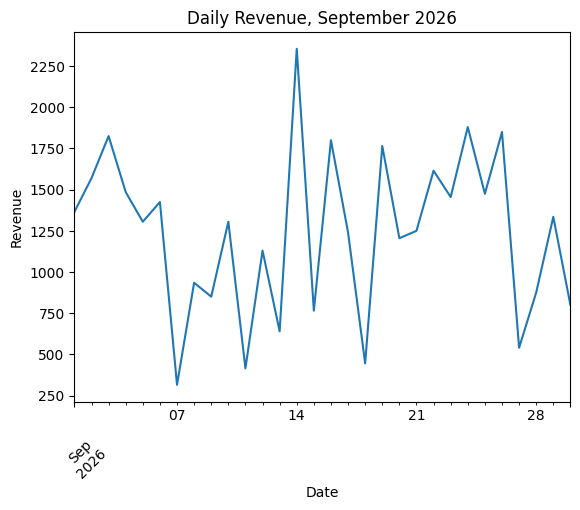

In [23]:
daily = df.groupby('Order_Date')['Revenue'].sum()
daily.plot(kind='line')
plt.title('Daily Revenue, September 2026'); plt.xlabel('Date'); plt.ylabel('Revenue')
plt.xticks(rotation=45); plt.show()

In [24]:
d = daily.reset_index()
d['Weekday'] = d['Order_Date'].dt.day_name()
order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
d.groupby('Weekday')['Revenue'].mean().reindex(order).round(1)

Weekday
Monday       1198.8
Tuesday      1203.0
Wednesday    1295.0
Thursday     1562.5
Friday        955.0
Saturday     1512.5
Sunday        952.5
Name: Revenue, dtype: float64